# 16 - Higher-order equations and boundary value problems

**MATH 331 - Differential Equations.** Lecture plan: Session 16 (Unit 7: equations of order n; boundary value problems; the deflection of a beam).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 2.3, Higher order linear ODEs** (Theorems 2.3.1 and
  2.3.2, Examples 2.3.3, 2.3.4, 2.3.5) and **Section 4.1, Boundary value problems** (Examples
  4.1.1, 4.1.2, 4.1.3, Theorem 4.1.2). Exercises 2.1.8, 2.3.2, 2.3.5, 2.3.12, 2.3.13, 2.3.14,
  4.1.7, 4.1.8, 4.1.9 (numbers of the lists at the end of the chapters).
* For the beam, which is not in the course texts: J. Kiusalaas, *Numerical Methods in
  Engineering with Python 3* (Cambridge University Press, 2013), Section 8.2, Example 8.4.
* Related notebooks: 05 (Wronskian; reduction of order), 06 (characteristic equation), 08 (linear
  systems), 15. Videos R06 (roots of polynomials), R08 (linear systems).

**What you will learn**
1. Equations of order $n$: $n$ constants, fixed by $n$ conditions at one point.
2. Constant coefficients with roots repeated any number of times.
3. Why conditions at **two** points can give one solution, none, or infinitely many.
4. How to compute the deflection of a beam.

## 1. Theory in brief

**Order $n$.** The general solution of a linear homogeneous equation of order $n$ is
$y = C_1y_1 + \dots + C_ny_n$, with $n$ independent solutions. Given $y(a), y'(a), \dots,
y^{(n-1)}(a)$ there is **exactly one** solution (Lebl, Theorem 2.3.2).

**Constant coefficients.** Try $e^{rx}$: the characteristic equation has degree $n$ and $n$
roots, counted with their multiplicity.

| Root | Solutions it gives |
|---|---|
| real $r$, $k$ times | $e^{rx},\ x\,e^{rx},\ \dots,\ x^{k-1}e^{rx}$ |
| pair $\alpha \pm i\beta$, $k$ times each | $x^je^{\alpha x}\cos\beta x$ and $x^je^{\alpha x}\sin\beta x$, for $j = 0, \dots, k - 1$ |

**Conditions for the constants.** Any $n$ conditions that are linear in $y$ form a linear system
$M\,C = b$ for the constants. The $n$ initial conditions $y(a), \dots, y^{(n-1)}(a)$ at **one**
point: $M$ is never singular (its determinant is the Wronskian at $a$). Conditions at **two**
points (a boundary value problem): $M$ can be singular, and then there is no solution or there
are infinitely many.

**The beam.** $E I\,y'''' = w(x)$, with **two** conditions at each end:

| End | Conditions |
|---|---|
| simply supported | $y = 0$, $y'' = 0$ |
| fixed | $y = 0$, $y' = 0$ |
| free | $y'' = 0$, $y''' = 0$ |

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: higher_order_solution, classify_linear_system, beam_deflection, check, check_solution).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. $n$ constants, $n$ initial conditions

*Lebl, Example 2.3.3.* $\;y''' - 3y'' - y' + 3y = 0$ has the solutions $e^{-x}$, $e^{x}$, $e^{3x}$
(notebook 06, Section 6), so $y = C_1e^{-x} + C_2e^{x} + C_3e^{3x}$. With $y(0) = 1$, $y'(0) = 2$,
$y''(0) = 3$ the three conditions are a linear system (video R08):

$$ \begin{pmatrix} 1 & 1 & 1 \\ -1 & 1 & 3 \\ 1 & 1 & 9 \end{pmatrix}
   \begin{pmatrix} C_1 \\ C_2 \\ C_3 \end{pmatrix} = \begin{pmatrix} 1 \\ 2 \\ 3 \end{pmatrix} . $$

Each row is one derivative of the three solutions at $x = 0$. The determinant of this matrix is
the Wronskian of the three solutions at 0, which is not zero because they are independent
(notebook 05): **whatever** numbers stand on the right, there is exactly one answer.

A consequence, with no computation (*Lebl, Exercise 2.3.14*):
$\;1001y''' + 3.2y'' + \pi y' - \sqrt4\,y = 0$ with $y(0) = y'(0) = y''(0) = 0$. The function $y = 0$
is a solution with these data, and there is only one: so $y = 0$.

In [2]:
x, t = sp.symbols("x t")

EXAMPLE_3 = (1, -3, -1, 3)                  # Lebl, Example 2.3.3: coefficients of y''', y'', y', y
START_3 = (1.0, 2.0, 3.0)                   # y(0), y'(0), y''(0)
basis = (sp.exp(-x), sp.exp(x), sp.exp(3 * x))

condition_matrix = np.array([[float(sp.diff(function, x, order).subs(x, 0)) for function in basis] for order in range(len(basis))])
kind, constants = ol.classify_linear_system(condition_matrix, START_3)
print(condition_matrix)
print("determinant:", round(np.linalg.det(condition_matrix), 6), "->", kind, "  C =", constants)

check_points = np.linspace(0.0, 1.0, 11)
by_constants = sum(value * sp.lambdify(x, function)(check_points) for value, function in zip(constants, basis))
assert np.allclose(constants, [-1 / 4, 1, 1 / 4])                                             # the values of the book
assert np.allclose(by_constants, ol.higher_order_solution(check_points, EXAMPLE_3, START_3))  # the library agrees

UGLY = (1001, 3.2, np.pi, -np.sqrt(4))      # Lebl, Exercise 2.3.14
print("Exercise 2.3.14, y at the same points:", ol.higher_order_solution(check_points, UGLY, (0.0, 0.0, 0.0)))

[[ 1.  1.  1.]
 [-1.  1.  3.]
 [ 1.  1.  9.]]
determinant: 16.0 -> one solution   C = [-0.25  1.    0.25]
Exercise 2.3.14, y at the same points: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 3. Roots of any multiplicity

**Finding the roots.** Lebl's advice for $r^3 - 3r^2 - r + 3$: try $-1$, $0$, $1$; look for a
change of sign (at $r = -2$ the value is $-15$, at $r = 0$ it is $3$: a root in between); when
one root $r_1$ is known, divide by $(r - r_1)$ (video R06). Or plot the polynomial, or ask the
computer: `sp.roots` gives each root with its multiplicity.

**Repeated roots.** *Lebl, Example 2.3.4.* $\;y'''' - 3y''' + 3y'' - y' = 0$:
$\;r^4 - 3r^3 + 3r^2 - r = r\,(r - 1)^3$. The root 1 **three** times, the root 0 once:

$$ y = (C_1 + C_2x + C_3x^2)\,e^{x} + C_4 . $$

*Lebl, Example 2.3.5.* $\;y'''' - 4y''' + 8y'' - 8y' + 4y = 0$:
$\;(r^2 - 2r + 2)^2$, the pair $1 \pm i$ **twice**:

$$ y = e^{x}\big((C_1 + C_2x)\cos x + (C_3 + C_4x)\sin x\big) . $$

Before running: how many constants are in the general solution of $y^{(5)} - y^{(4)} = 0$, and
which functions? (*Lebl, Exercise 2.3.12.*)

(r - 3)*(r - 1)*(r + 1)    roots and multiplicities: {3: 1, 1: 1, -1: 1}
r*(r - 1)**3    roots and multiplicities: {1: 3, 0: 1}


(r**2 - 2*r + 2)**2    roots and multiplicities: {1 - I: 2, 1 + I: 2}


r**4*(r - 1)    roots and multiplicities: {1: 1, 0: 4}


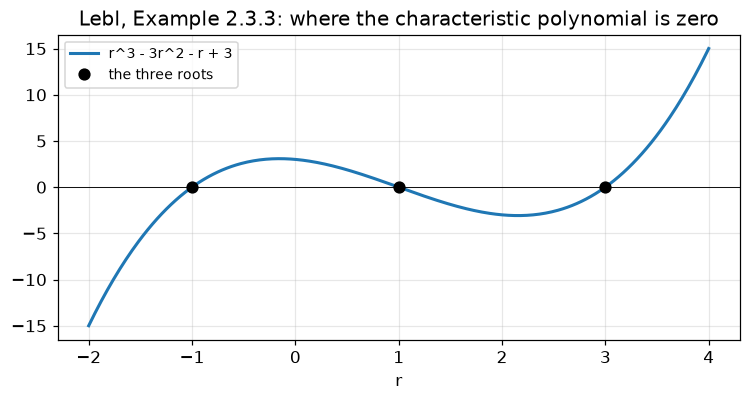

In [3]:
r = sp.symbols("r")
C = sp.symbols("C1:6")
FIGURE_SIZE = (8.0, 3.6)
N_POINTS = 400
R_RANGE = (-2.0, 4.0)


def left_side(y, coefficients):
    # a_n y^(n) + ... + a_0 y for a formula y; coefficients a_n, ..., a_0
    order = len(coefficients) - 1
    return sum(value * sp.diff(y, x, order - index) for index, value in enumerate(coefficients))


EXAMPLE_4 = (1, -3, 3, -1, 0)               # Lebl, Example 2.3.4
EXAMPLE_5 = (1, -4, 8, -8, 4)               # Lebl, Example 2.3.5
TWELVE = (1, -1, 0, 0, 0, 0)                # Lebl, Exercise 2.3.12
general = {EXAMPLE_4: (C[0] + C[1] * x + C[2] * x ** 2) * sp.exp(x) + C[3],
           EXAMPLE_5: sp.exp(x) * ((C[0] + C[1] * x) * sp.cos(x) + (C[2] + C[3] * x) * sp.sin(x)),
           TWELVE: C[0] * sp.exp(x) + C[1] * x ** 3 + C[2] * x ** 2 + C[3] * x + C[4]}

for coefficients in (EXAMPLE_3, EXAMPLE_4, EXAMPLE_5, TWELVE):
    polynomial = sum(value * r ** (len(coefficients) - 1 - index) for index, value in enumerate(coefficients))
    print(sp.factor(polynomial), "   roots and multiplicities:", sp.roots(polynomial, r))
    if coefficients in general:
        assert sp.simplify(left_side(general[coefficients], coefficients)) == 0      # the general solution, substituted

values = np.linspace(*R_RANGE, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(values, np.polyval(EXAMPLE_3, values), "-", linewidth=2, label="r^3 - 3r^2 - r + 3")
ax.plot(np.roots(EXAMPLE_3).real, np.zeros(3), "o", color="black", markersize=7, label="the three roots")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("r")
ax.set_title("Lebl, Example 2.3.3: where the characteristic polynomial is zero")
ax.legend(loc="upper left")
plt.show()

*The plot shows* the polynomial $r^3 - 3r^2 - r + 3$ for $-2 \le r \le 4$: it rises from $-15$,
crosses zero at $r = -1$, reaches about $3.1$, crosses again at $r = 1$, dips to about $-3.1$ and
crosses a third time at $r = 3$ (black dots), ending at 15.

(Answer: five constants. The root 0 four times gives $1, x, x^2, x^3$, and the root 1 gives
$e^x$: $\;y = C_1e^x + C_2x^3 + C_3x^2 + C_4x + C_5$.)

## 4. One solution gives another

When the coefficients are not constant there is no characteristic equation. But if **one**
solution $y_1$ is known, a second one comes from $y_2 = y_1\,v$: the equation for $v'$ is of first
order. This is **reduction of order**, done in notebook 05, Section 6.

*Lebl, Exercise 2.1.8* (Chebyshev's equation of order 1). $\;(1 - x^2)\,y'' - x\,y' + y = 0$ has
the solution $y_1 = x$. Dividing by $1 - x^2$: $p = -\dfrac{x}{1 - x^2}$, so $\int p = \tfrac12\ln(1 - x^2)$ and
$e^{-\int p} = 1/\sqrt{1 - x^2}$. The formula of notebook 05 gives

$$ v' = \frac{e^{-\int p}}{y_1^2} = \frac{1}{x^2\sqrt{1 - x^2}}, \qquad v = -\frac{\sqrt{1 - x^2}}{x},
   \qquad y_2 = y_1v = -\sqrt{1 - x^2} \quad (-1 < x < 1) . $$

($v$ is not defined at $x = 0$, but $y_2$ is a solution on the whole interval: the code checks it.)

In [4]:
first = x
p = -x / (1 - x ** 2)
v = -sp.sqrt(1 - x ** 2) / x
second = sp.simplify(first * v)
assert sp.simplify(sp.diff(v, x) - 1 / (x ** 2 * sp.sqrt(1 - x ** 2))) == 0      # an integral is checked by differentiating
assert sp.simplify(sp.diff(sp.log(sp.sqrt(1 - x ** 2)), x) - p) == 0             # so exp(-integral of p) = 1 / sqrt(1 - x^2)
for solution in (first, second):
    assert sp.simplify((1 - x ** 2) * sp.diff(solution, x, 2) - x * sp.diff(solution, x) + solution) == 0
print("y_2 =", second, "  Wronskian:", sp.simplify(first * sp.diff(second, x) - sp.diff(first, x) * second))

y_2 = -sqrt(1 - x**2)   Wronskian: 1/sqrt(1 - x**2)


## 5. Conditions at two points

Now the letters of Lebl's Section 4.1: $x(t)$, and a number $\lambda > 0$.

$$ x'' + \lambda\,x = 0 \ \text{ on } 0 \le t \le \pi, \qquad x(0) = 0, \quad x(\pi) = h . $$

Two constants and two conditions, as for an initial value problem; but the conditions are at
**two different points**. The general solution is $x = A\cos\sqrt\lambda\,t + B\sin\sqrt\lambda\,t$,
and the conditions are

$$ \begin{pmatrix} 1 & 0 \\ \cos\sqrt\lambda\,\pi & \sin\sqrt\lambda\,\pi \end{pmatrix}
   \begin{pmatrix} A \\ B \end{pmatrix} = \begin{pmatrix} 0 \\ h \end{pmatrix}, \qquad
   \text{determinant} = \sin\sqrt\lambda\,\pi . $$

So $A = 0$ and $B\,\sin\sqrt\lambda\,\pi = h$. Three cases, by hand:

* *Lebl, Example 4.1.2*: $\lambda = 2$, $h = 0$. $\sin\sqrt2\,\pi \ne 0$, so $B = 0$: **only**
  $x = 0$. (With $h = 1$: exactly one solution, $B = 1/\sin\sqrt2\,\pi$.)
* *Lebl, Example 4.1.1*: $\lambda = 1$, $h = 0$. $\sin\pi = 0$: the equation $B \cdot 0 = 0$ holds
  for every $B$. **Infinitely many** solutions, $x = B\sin t$.
* $\lambda = 1$, $h = 1$. $B \cdot 0 = 1$: **no solution**.

The rule behind it: if the problem with **zero** boundary values has only the zero solution,
the problem has exactly one solution for every pair of boundary values; if it has other
solutions, it has none or infinitely many. (Lebl, Theorem 4.1.2, the Fredholm alternative,
states the same for an equation with a right-hand side $f(t)$.) The values of $\lambda$ for
which the problem with zero boundary values has a solution that is not zero are the
**eigenvalues**; here they are
$\lambda = 1, 4, 9, \dots$ (Lebl, Example 4.1.3).

lambda = 2, x(pi) = 0: determinant -0.964 -> one solution
lambda = 2, x(pi) = 1: determinant -0.964 -> one solution
lambda = 1, x(pi) = 0: determinant +0.000 -> infinitely many solutions
lambda = 1, x(pi) = 1: determinant +0.000 -> no solution


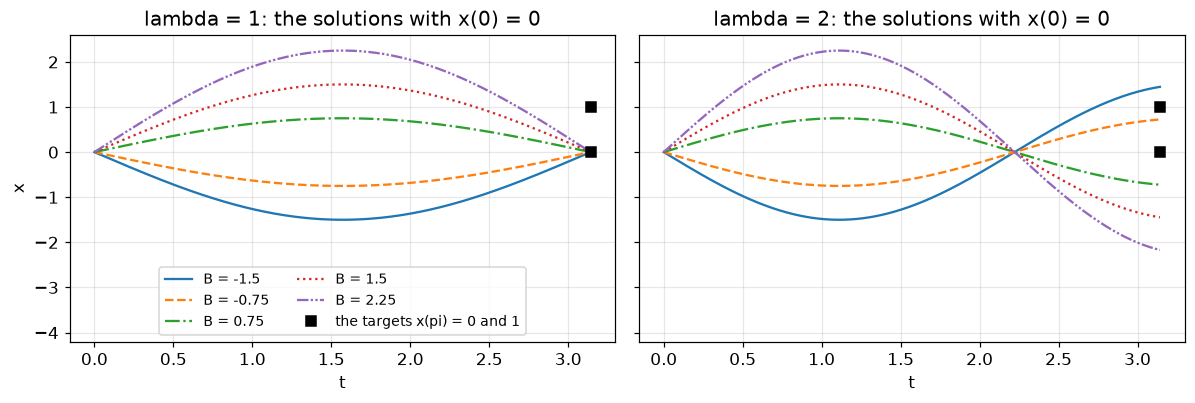

In [5]:
T_END = np.pi
SHOTS = (-1.5, -0.75, 0.75, 1.5, 2.25)       # values of B
SHOT_STYLES = ("-", "--", "-.", ":", (0, (5, 1, 1, 1, 1, 1)))
WIDE_FIGURE = (11.0, 3.8)
SHOT_WINDOW = (-4.2, 2.6)


def end_conditions(lam):
    # the matrix of the two conditions x(0) = ..., x(pi) = ... for the constants A, B
    root = np.sqrt(lam)
    return np.array([[1.0, 0.0], [np.cos(root * T_END), np.sin(root * T_END)]])


for lam, target in ((2.0, 0.0), (2.0, 1.0), (1.0, 0.0), (1.0, 1.0)):
    kind, constants = ol.classify_linear_system(end_conditions(lam), [0.0, target])
    print(f"lambda = {lam:g}, x(pi) = {target:g}: determinant {np.sin(np.sqrt(lam) * T_END):+.3f} -> {kind}")
assert ol.classify_linear_system(end_conditions(1.0), [0.0, 1.0])[0] == "no solution"
assert ol.classify_linear_system(end_conditions(1.0), [0.0, 0.0])[0] == "infinitely many solutions"

times = np.linspace(0.0, T_END, N_POINTS)
fig, panels = plt.subplots(1, 2, figsize=WIDE_FIGURE, sharey=True)
for panel, lam in zip(panels, (1.0, 2.0)):
    for size, style in zip(SHOTS, SHOT_STYLES):
        panel.plot(times, size * np.sin(np.sqrt(lam) * times), linestyle=style, linewidth=1.5, label=f"B = {size:g}")
    panel.plot([T_END, T_END], [0.0, 1.0], "s", color="black", markersize=7, label="the targets x(pi) = 0 and 1")
    panel.set_xlabel("t")
    panel.set_title(f"lambda = {lam:g}: the solutions with x(0) = 0")
panels[0].set_ylabel("x")
panels[0].set_ylim(*SHOT_WINDOW)                                                  # room for the legend
panels[0].legend(loc="lower center", ncol=2)
plt.tight_layout()
plt.show()

*The plot shows* the solutions that start at $x(0) = 0$, for five values of $B$ (five line
styles), and two black squares: the targets $x(\pi) = 0$ and $x(\pi) = 1$. Left, $\lambda = 1$:
**all** the curves $B\sin t$ arrive at 0. The target 0 is hit by every one of them, the target 1
by none. Right, $\lambda = 2$: the curves arrive at five different heights, between $-2.2$ and
$1.4$: each target is hit by exactly one value of $B$.

**Slider.** Before moving it: with $x(0) = 0$ and $x(\pi) = 1$, what happens to the solution as
$\lambda$ approaches 1? And just after 1?

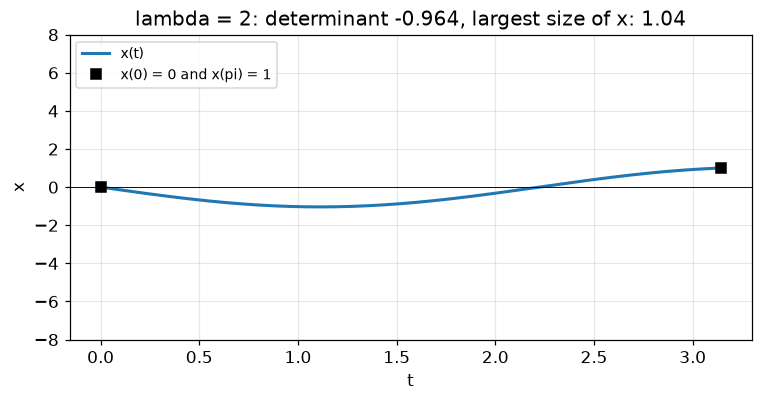

In [6]:
DEFAULT_LAMBDA = 2.0
LAMBDA_RANGE = (0.2, 10.0, 0.1)             # minimum, maximum, step
WINDOW = 8.0                                # the picture shows x between -WINDOW and WINDOW


def plot_bvp(lam=DEFAULT_LAMBDA):
    # the solution of x'' + lam x = 0, x(0) = 0, x(pi) = 1, when there is exactly one
    kind, constants = ol.classify_linear_system(end_conditions(lam), [0.0, 1.0])
    times = np.linspace(0.0, T_END, N_POINTS)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    if kind == "one solution":
        solution = constants[0] * np.cos(np.sqrt(lam) * times) + constants[1] * np.sin(np.sqrt(lam) * times)
        ax.plot(times, np.clip(solution, -2 * WINDOW, 2 * WINDOW), "-", linewidth=2, label="x(t)")
        ax.set_title(f"lambda = {lam:g}: determinant {np.sin(np.sqrt(lam) * T_END):+.3f}, "
                     f"largest size of x: {np.max(np.abs(solution)):.3g}")
    else:
        ax.set_title(f"lambda = {lam:g} is an eigenvalue: {kind}")
    ax.plot([0.0, T_END], [0.0, 1.0], "s", color="black", markersize=7, label="x(0) = 0 and x(pi) = 1")
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_ylim(-WINDOW, WINDOW)
    ax.set_xlabel("t")
    ax.set_ylabel("x")
    ax.legend(loc="upper left")
    plt.show()


plot_bvp()

In [7]:
interact(plot_bvp,
         lam=FloatSlider(value=DEFAULT_LAMBDA, min=LAMBDA_RANGE[0], max=LAMBDA_RANGE[1], step=LAMBDA_RANGE[2],
                         description="lambda", continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='lambda', max=10.0, min=0.2)...

*The static plot shows*, for $\lambda = 2$, the one solution through the two black squares
$(0, 0)$ and $(\pi, 1)$: it first goes **down**, to $-1.04$ near $t = 1.1$, and comes back up to 1.
The determinant is $-0.964$.

(Answer: as $\lambda \to 1$ the determinant tends to 0 and the solution grows without bound: its
largest size is 6.2 at $\lambda = 0.9$ and 63.5 at $\lambda = 0.99$ (try `plot_bvp(lam=0.99)`). Just after 1 it is as large,
with the opposite sign. The same happens at 4 and at 9. It is the picture of notebook 15: a
response that explodes near special values, here the eigenvalues, there the natural frequency.)

## 6. The deflection of a beam

Back to $y(x)$: the **deflection** of a horizontal beam at the position $x$, positive downwards.
For small deflections (beam theory):

* $y'$ is the slope; $E I\,y''$ the bending moment; $E I\,y'''$ the shear force;
* $E I\,y'''' = w(x)$, the load per unit length. $E I$ is the **bending rigidity** (material
  times shape of the cross-section).

The homogeneous equation $y'''' = 0$ has the root 0 four times (Section 3): $y_c$ is a cubic.
So the general solution is "integrate $w$ four times, add a cubic", and the **four** constants
come from two conditions at each end (the table of Section 1). At one end one may prescribe the
deflection or the shear force, not both, and the slope or the moment, not both (Kiusalaas,
Section 8.3).

*Kiusalaas, Example 8.4.* A simply supported beam of length $L$ with the load $w_0x/L$, zero at
the left end and largest at the right. With $\xi = x/L$ and $y$ measured in units of
$w_0L^4/(EI)$:

$$ y'''' = \xi, \qquad y(0) = y''(0) = 0, \quad y(1) = y''(1) = 0 . $$

By hand: $y = \dfrac{\xi^5}{120} + C_1\xi^3 + C_2\xi^2 + C_3\xi + C_4$. At $\xi = 0$: $C_4 = 0$ and
$C_2 = 0$. At $\xi = 1$: $y'' = \tfrac16 + 6C_1 = 0$ gives $C_1 = -\tfrac1{36}$, and then
$y = \tfrac1{120} - \tfrac1{36} + C_3 = 0$ gives $C_3 = \tfrac{7}{360}$:

$$ y = \frac{\xi^5}{120} - \frac{\xi^3}{36} + \frac{7\,\xi}{360} . $$

The system for the constants was not singular: a beam held at both ends has exactly one shape.

slopes at the ends: 7/360 = 0.019444 and -1/45 = -0.022222;  mid-span: 5/768 = 0.0065104


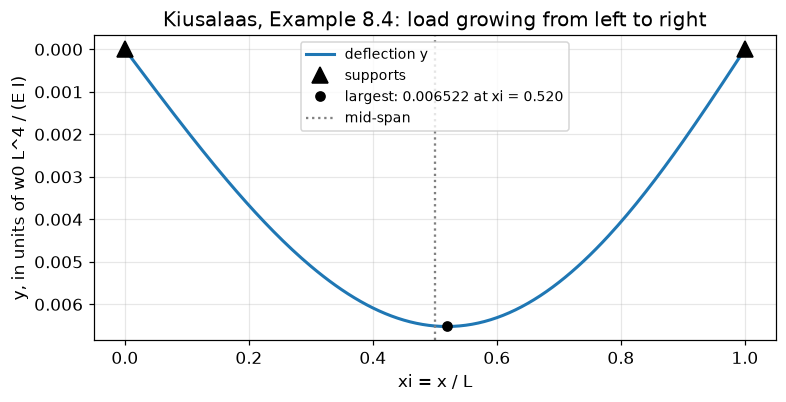

In [8]:
xi = sp.symbols("xi")
KIUSALAAS_LOAD = [1.0, 0.0]                 # the load xi: coefficients of xi^1 and xi^0
N_BEAM = 201

shape = xi ** 5 / 120 - xi ** 3 / 36 + 7 * xi / 360
assert sp.diff(shape, xi, 4) == xi
assert all(sp.diff(shape, xi, order).subs(xi, end) == 0 for order in (0, 2) for end in (0, 1))
slope_left, slope_right, middle = sp.diff(shape, xi).subs(xi, 0), sp.diff(shape, xi).subs(xi, 1), shape.subs(xi, sp.Rational(1, 2))
print(f"slopes at the ends: {slope_left} = {float(slope_left):.6f} and {slope_right} = {float(slope_right):.6f};  "
      f"mid-span: {middle} = {float(middle):.7f}")
assert np.allclose([float(slope_left), float(slope_right), float(middle)], [19.444e-3, -22.222e-3, 6.5104e-3], atol=5e-7)  # the book

positions = np.linspace(0.0, 1.0, N_BEAM)
deflection = ol.beam_deflection(positions, KIUSALAAS_LOAD, "supported", "supported")
assert np.allclose(deflection, sp.lambdify(xi, shape)(positions))                       # the library agrees
deepest = positions[np.argmax(deflection)]

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(positions, deflection, "-", linewidth=2, label="deflection y")
ax.plot([0.0, 1.0], [0.0, 0.0], "^", color="black", markersize=10, label="supports")
ax.plot(deepest, deflection.max(), "o", color="black", markersize=6, label=f"largest: {deflection.max():.6f} at xi = {deepest:.3f}")
ax.axvline(0.5, linestyle=":", color="gray", label="mid-span")
ax.invert_yaxis()                                                                       # downwards is down
ax.set_xlabel("xi = x / L")
ax.set_ylabel("y, in units of w0 L^4 / (E I)")
ax.set_title("Kiusalaas, Example 8.4: load growing from left to right")
ax.legend(loc="upper center")
plt.show()

*The plot shows* the beam, drawn with "down" downwards: it hangs between the two supports
(triangles) like a shallow bowl, a little deeper on the right, where the load is heavier. The
deepest point (black dot) is 0.006522 at $\xi = 0.52$, just right of the dotted mid-span line,
where the deflection is $5/768 = 0.0065104$: the number printed in the book.

**A uniform load, three ways of holding the beam.** With $w = w_0$ the same four integrations
give the classical results:

| Supports | Largest deflection, in units of $w_0L^4/(EI)$ |
|---|---|
| fixed at both ends | $\tfrac{1}{384}$, at mid-span |
| simply supported at both ends | $\tfrac{5}{384}$, at mid-span |
| fixed at the left, free at the right (cantilever) | $\tfrac18 = \tfrac{48}{384}$, at the free end |

**Sliders.** Before moving them: the load is made heavier on the right, with the same total. On
the cantilever (fixed on the left), does the free end go down more, or less?

fixed     - fixed    : largest deflection 0.002604
supported - supported: largest deflection 0.013021
fixed     - free     : largest deflection 0.125000


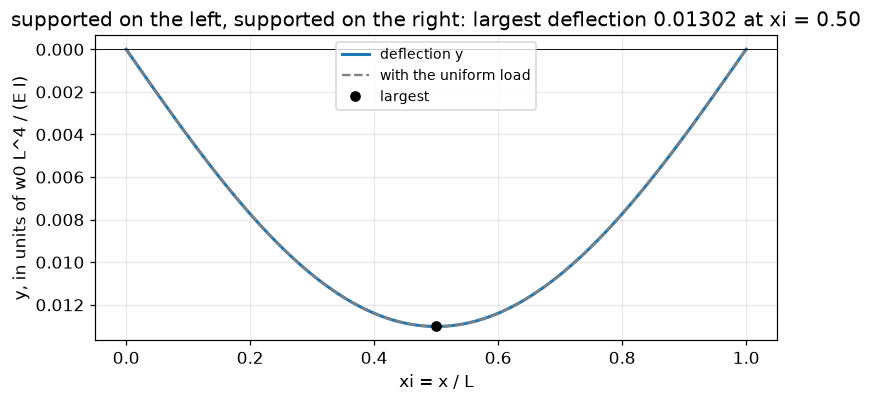

In [9]:
HOLDINGS = (("fixed", "fixed"), ("supported", "supported"), ("fixed", "free"))
BEAM_DEFAULTS = {"holding": 1, "uneven": 0.0}
UNEVEN_RANGE = (-1.0, 1.0, 0.1)             # minimum, maximum, step

for left, right in HOLDINGS:
    print(f"{left:9s} - {right:9s}: largest deflection {np.max(ol.beam_deflection(positions, [1.0], left, right)):.6f}")
assert np.isclose(np.max(ol.beam_deflection(positions, [1.0], "fixed", "fixed")), 1 / 384)
assert np.isclose(np.max(ol.beam_deflection(positions, [1.0], "supported", "supported")), 5 / 384)
assert np.isclose(ol.beam_deflection(1.0, [1.0], "fixed", "free"), 1 / 8)


def plot_beam(holding=BEAM_DEFAULTS["holding"], uneven=BEAM_DEFAULTS["uneven"]):
    # the deflection under the load 1 + uneven (2 xi - 1): total 1, heavier on the right when uneven > 0
    left, right = HOLDINGS[holding]
    deflection = ol.beam_deflection(positions, [2 * uneven, 1 - uneven], left, right)
    even = ol.beam_deflection(positions, [1.0], left, right)
    deepest = np.argmax(np.abs(deflection))
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(positions, deflection, "-", linewidth=2, label="deflection y")
    ax.plot(positions, even, "--", color="gray", label="with the uniform load")
    ax.plot(positions[deepest], deflection[deepest], "o", color="black", markersize=6, label="largest")
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.invert_yaxis()
    ax.set_xlabel("xi = x / L")
    ax.set_ylabel("y, in units of w0 L^4 / (E I)")
    ax.set_title(f"{left} on the left, {right} on the right: largest deflection "
                 f"{abs(deflection[deepest]):.5f} at xi = {positions[deepest]:.2f}")
    ax.legend(loc="upper center")
    plt.show()


plot_beam()

In [10]:
interact(plot_beam,
         holding=IntSlider(value=BEAM_DEFAULTS["holding"], min=0, max=len(HOLDINGS) - 1, description="supports",
                           continuous_update=False),
         uneven=FloatSlider(value=BEAM_DEFAULTS["uneven"], min=UNEVEN_RANGE[0], max=UNEVEN_RANGE[1], step=UNEVEN_RANGE[2],
                            description="uneven", continuous_update=False));

interactive(children=(IntSlider(value=1, continuous_update=False, description='supports', max=2), FloatSlider(...

*The static plot shows* the simply supported beam under the uniform load (slider "supports" at
1, "uneven" at 0): a symmetric bowl, deepest at mid-span, $5/384 = 0.01302$. The dashed curve,
the uniform load, lies exactly on it. Position 0 of the first slider is the beam fixed at both
ends, position 2 the cantilever.

(Answer: more. With "uneven" at 1 the load is $2\xi$ and the free end goes down to $0.18333$
against $0.125$: load far from the fixed end counts more.)

## 7. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* *(Lebl, Exercise 2.3.14)* For $1001y''' + 3.2y'' + \pi y' - \sqrt4\,y = 0$ with
  $y(0) = y'(0) = y''(0) = 0$: what is $y(1)$?
* *(Lebl, Exercise 2.3.12)* For $y^{(5)} - y^{(4)} = 0$: how many constants are in the general
  solution? How many of the five functions in it are polynomials?
* How many solutions (write `0`, `1` or `np.inf`) have these three problems, in this order?
  $x'' + x = 0$, $x(0) = 0$, $x(\pi) = 0$; $\quad x'' + x = 0$, $x(0) = 0$, $x(\pi) = 1$;
  $\quad x'' + 2x = 0$, $x(0) = 0$, $x(\pi) = 1$.

In [11]:
my_value_at_1 = None
my_constants = None
my_polynomials = None
my_numbers_of_solutions = None  # a list of three, for example [1, 1, 1]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 1, y(1)", my_value_at_1, 0.0)
ol.check("Exercise 1, constants", my_constants, len(TWELVE) - 1)
ol.check("Exercise 1, polynomials", my_polynomials, sp.roots(r ** 5 - r ** 4, r)[0])
COUNTS = {"one solution": 1, "no solution": 0, "infinitely many solutions": np.inf}
expected_counts = [COUNTS[ol.classify_linear_system(end_conditions(lam), [0.0, target])[0]]
                   for lam, target in ((1.0, 0.0), (1.0, 1.0), (2.0, 1.0))]
if my_numbers_of_solutions is None:
    print("Exercise 1, numbers of solutions: no answer yet (replace None with your list)")
elif isinstance(my_numbers_of_solutions, (list, tuple, np.ndarray)) and list(my_numbers_of_solutions) == expected_counts:
    print("Exercise 1, numbers of solutions: correct")
else:
    print("Exercise 1, numbers of solutions: not yet (a list of three, each 0, 1 or np.inf)")

Exercise 1, y(1): no answer yet (replace None with your value)
Exercise 1, constants: no answer yet (replace None with your value)
Exercise 1, polynomials: no answer yet (replace None with your value)
Exercise 1, numbers of solutions: no answer yet (replace None with your list)


### Exercise 2 - By hand, then check

**(a)** *From Lebl, Exercise 2.3.2.* $\;y'''' - 5y''' + 6y'' = 0$: the four roots of the characteristic
equation, with repetitions, in increasing order.

**(b)** *Lebl, Exercise 2.3.13.* A third-order equation whose characteristic roots are $3$ and
$\pm 2i$: its four coefficients, starting with 1 for $y'''$.

**(c)** *Lebl, Exercise 4.1.8.* $\;x'' + x = 0$, $x(0) = 0$, $x'(\pi) = 1$. Type the solution as a
SymPy formula in `t`.

**(d)** *From Lebl, Exercise 2.1.8.* The solution of Chebyshev's equation
$(1 - x^2)\,y'' - x\,y' + y = 0$ with $y(0) = 1$, $y'(0) = 0$, as a SymPy formula in `x`.

In [12]:
my_roots = None                 # (a) a list of four numbers
my_coefficients = None          # (b) a list of four numbers
my_x = None                     # (c)
my_y = None                     # (d)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 2a", my_roots, sorted(float(value) for value, times_ in sp.roots(r ** 4 - 5 * r ** 3 + 6 * r ** 2, r).items()
                                         for repeat in range(times_)))
ol.check("Exercise 2b", my_coefficients, [float(value) for value in sp.Poly(sp.expand((r - 3) * (r ** 2 + 4)), r).all_coeffs()])
ol.check_solution("Exercise 2c", my_x, lambda u: sp.diff(u, t, 2) + u, t, (0.0, 3.0),
                  conditions=((0, 0), (sp.pi, 1, 1)))            # x(0) = 0 and x'(pi) = 1
ol.check_solution("Exercise 2d", my_y, lambda u: (1 - x ** 2) * sp.diff(u, x, 2) - x * sp.diff(u, x) + u, x, (-0.5, 0.5),
                  conditions=((0, 1), (0, 0, 1)));               # y(0) = 1 and y'(0) = 0

Exercise 2a: no answer yet (replace None with your value)
Exercise 2b: no answer yet (replace None with your value)
Exercise 2c: no answer yet (replace None with your formula)
Exercise 2d: no answer yet (replace None with your formula)


### Exercise 3 - Fill in

Section 6 found the deflection at mid-span of a simply supported beam under a uniform load in
units of $w_0L^4/(EI)$. Put the units back: complete `midspan_deflection`, which takes the load
$w_0$ (N/m), the length $L$ (m) and the rigidity $EI$ (N m$^2$) and returns the deflection in
metres. The next cell compares it with a numerical solution of the boundary value problem and
then uses it for a steel beam.

In [13]:
def midspan_deflection(w0, L, EI):
    return None                 # replace None with the formula

In [14]:
BEAMS = ((1.0e4, 6.0, 210e9 * 8.356e-5), (2.5e3, 4.0, 1.2e6), (1.0, 1.0, 1.0))      # w0, L, EI
STEEL = BEAMS[0]                # numbers chosen for this exercise: 10 kN/m on 6 m, E = 210 GPa, I = 8.356e-5 m^4
ALLOWED_FRACTION = 1 / 300      # a common limit: the deflection must stay below L / 300
BVP_TOLERANCE = 1e-8
FORMULA_TOLERANCE = 1e-3            # accepts 0.01302 in place of 5/384

mesh = np.linspace(0.0, 1.0, 21)
numerical = solve_bvp(lambda s, u: np.vstack([u[1], u[2], u[3], np.ones_like(s)]),             # Y'''' = 1
                      lambda ua, ub: np.array([ua[0], ua[2], ub[0], ub[2]]),                    # Y = Y'' = 0 at both ends
                      mesh, np.zeros((4, mesh.size)), tol=BVP_TOLERANCE)
middle_value = float(numerical.sol(0.5)[0])                                                   # no formula is used

try:
    answers = [midspan_deflection(*beam) for beam in BEAMS]
    wrong = None if answers[0] is None else [beam for beam, answer in zip(BEAMS, answers) if not np.isclose(
        float(answer), beam[0] * beam[1] ** 4 / beam[2] * middle_value, rtol=FORMULA_TOLERANCE)]
except Exception as problem:                               # whatever goes wrong inside the function
    answers, wrong = [type(problem).__name__], None
if answers[0] is None:
    print("Exercise 3: complete midspan_deflection first")
else:
    if wrong is None:
        print("Exercise 3: not yet (midspan_deflection must return one number, computed from w0, L and EI)")
    elif wrong:
        w0, L, EI = wrong[0]
        print(f"Exercise 3: not yet. For w0 = {w0:g} N/m, L = {L:g} m, EI = {EI:g} N m^2 the numerical solution gives "
              f"{w0 * L ** 4 / EI * middle_value:.4g} m; your formula gives {float(midspan_deflection(w0, L, EI)):.4g} m")
    else:
        sag = midspan_deflection(*STEEL)
        print(f"Exercise 3: correct on all {len(BEAMS)} beams")
        print(f"The steel beam goes down {1000 * sag:.1f} mm at mid-span; the limit L / 300 is {1000 * STEEL[1] * ALLOWED_FRACTION:.0f} mm: "
              f"{'acceptable' if sag < STEEL[1] * ALLOWED_FRACTION else 'too much'}")

Exercise 3: complete midspan_deflection first


### Exercise 4 - Explore

* *(Lebl, Exercise 4.1.7)* $x'' + \lambda x = 0$, $x(0) = 1$, $x(1) = 1$. For which $\lambda > 0$
  is there more than one solution? (Write the two conditions as a system for $A$, $B$ and ask
  `ol.classify_linear_system`, or work by hand.)
* With the sliders of Section 6, compare the largest deflection under a uniform load for the
  three ways of holding the beam. Then find by hand the deflection of the cantilever.
* *(Lebl, Exercise 2.3.5)* Find a fourth-order equation that has the solution $2e^{4x}x\cos x$.
* *(Lebl, Exercise 4.1.9)* Why can $x' + \lambda x = 0$ with $x(0) = 0$, $x(1) = 0$ never have a
  solution that is not zero?

In [15]:
# your code here: for example
# ol.classify_linear_system([[1.0, 0.0], [np.cos(2 * np.pi), np.sin(2 * np.pi)]], [1.0, 1.0])

## 8. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. $y(1) = 0$ (the solution is zero everywhere). Five constants; four polynomials
   ($1, x, x^2, x^3$). `[np.inf, 0, 1]`.
2. (a) `[0, 0, 2, 3]`. (b) `[1, -3, 4, -12]`: $(r - 3)(r^2 + 4) = r^3 - 3r^2 + 4r - 12$.
   (c) $x = -\sin t$. (d) $y = \sqrt{1 - x^2}$.
3. `return 5 * w0 * L ** 4 / (384 * EI)`; the steel beam goes down 9.6 mm, below the 20 mm
   allowed.
4. $\lambda = 4k^2\pi^2$, $k = 1, 2, \dots$ (then $x = \cos 2k\pi t + B\sin 2k\pi t$ for every $B$).
   $1 : 5 : 48$; the cantilever is $y = \tfrac{1}{24}\xi^2(\xi^2 - 4\xi + 6)$, which is $\tfrac18$ at
   $\xi = 1$. The roots must be $4 \pm i$, twice each: $(r^2 - 8r + 17)^2$, that is
   $y'''' - 16y''' + 98y'' - 272y' + 289y = 0$. The general solution $Ce^{-\lambda t}$ has one
   constant: $x(0) = 0$ already gives $C = 0$.

</details>

**Where to go next:** notebook 17, where an equation of order $n$ becomes a system of $n$
equations of order 1 (this is how `ol.higher_order_solution` works). The eigenvalues of Section 5
come back with Fourier series.